# 03 · Foundation component: CLIP inside the system

In [1]:
import os, sys
REPO_URL = "https://github.com/YUPWE/car-size.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/car-size"
    if not os.path.exists(ROOT):
        !git clone {REPO_URL} {ROOT}
    os.chdir(ROOT)
    !git pull -q
    !pip install -q imagehash==4.3.2
    os.environ["CARS_DATA_DIR"] = "/content/cars_data"
else:
    ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
    os.chdir(ROOT)
sys.path.insert(0, ROOT)
os.makedirs("results", exist_ok=True)
os.makedirs("weights", exist_ok=True)
QUICK = os.environ.get("QUICK", "0") == "1"
print("Working in", os.getcwd(), "| QUICK =", QUICK)

Mounted at /content/drive
Working in /content/drive/MyDrive/car-size | QUICK = False


In [2]:
import numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from sklearn.metrics import f1_score, accuracy_score, log_loss
from src import data
from src.data import CLASSES, CarDataset, get_transforms
from src.model import build_resnet18, predict_probs, get_device
from src.clip_gate import ClipZeroShot, load_pil
from src.system import save_config

data.download()
device = get_device()
val_df = data.load_split("val")
if QUICK: val_df = val_df.sample(32, random_state=0)
y_val = np.array([CLASSES.index(l) for l in val_df.label])

resnet = build_resnet18(freeze_backbone=False, pretrained=False)
resnet.load_state_dict(torch.load("weights/resnet18_finetuned.pt", map_location=device))
resnet.to(device)
p_res, _ = predict_probs(resnet, DataLoader(CarDataset(val_df, get_transforms(False)), batch_size=128), device)

clip = ClipZeroShot(device=device)
p_clip, oos_val = clip(load_pil(f"{data.IMG_DIR}/{p}" for p in val_df.path))

for name, p in [("CLIP zero-shot (no training)", p_clip), ("ResNet-18 fine-tuned", p_res)]:
    pred = p.argmax(1)
    print(f"{name:30s} val acc {accuracy_score(y_val, pred):.3f} | macro-F1 {f1_score(y_val, pred, average='macro'):.3f}")

Unzipping cached images ...


config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

... (4 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP zero-shot (no training)   val acc 0.949 | macro-F1 0.941
ResNet-18 fine-tuned           val acc 0.961 | macro-F1 0.955


## Job 2 — choose the mixing weight `w`

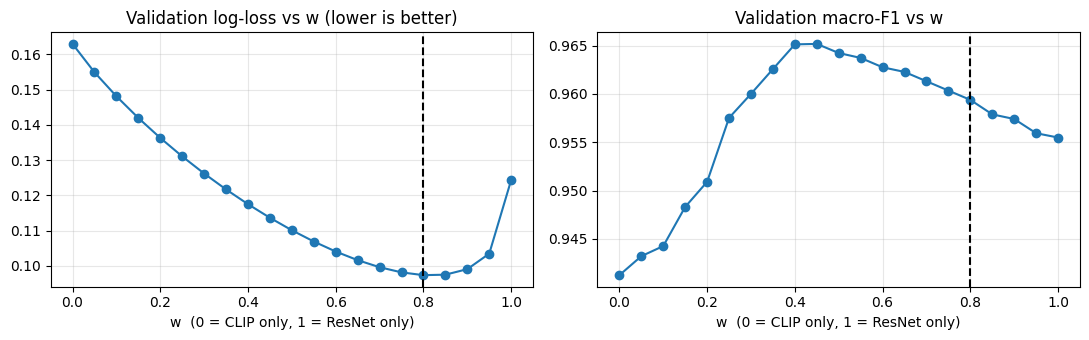

chosen w = 0.8 | val macro-F1 at w: 0.959 | ResNet only: 0.955


In [3]:
def mixed(w):
    m = np.clip(w * p_res + (1 - w) * p_clip, 1e-7, 1)
    return m / m.sum(1, keepdims=True)

ws = np.round(np.linspace(0, 1, 21), 2)
losses = [log_loss(y_val, mixed(w), labels=[0, 1]) for w in ws]
f1s = [f1_score(y_val, mixed(w).argmax(1), average="macro") for w in ws]
best_w = float(ws[int(np.argmin(losses))])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ws, losses, "o-"); ax[0].axvline(best_w, ls="--", c="k"); ax[0].set_title("Validation log-loss vs w (lower is better)")
ax[1].plot(ws, f1s, "o-"); ax[1].axvline(best_w, ls="--", c="k"); ax[1].set_title("Validation macro-F1 vs w")
for a in ax: a.set_xlabel("w  (0 = CLIP only, 1 = ResNet only)"); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig("results/mixing_weight.png", dpi=120); plt.show()
print("chosen w =", best_w, "| val macro-F1 at w:", round(f1s[int(np.argmin(losses))], 3), "| ResNet only:", round(f1s[-1], 3))

## Job 1 — the not-a-car gate

chosen not-a-car threshold = 0.3 -> rejects 0.0% of validation car photos


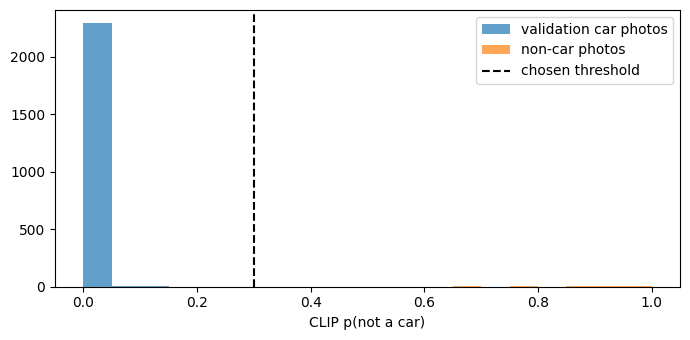

non-car photos rejected: 18 / 18
  astronaut              p(not a car) = 0.85 -> rejected
  chelsea                p(not a car) = 0.95 -> rejected
  coffee                 p(not a car) = 0.52 -> rejected
  rocket                 p(not a car) = 0.66 -> rejected
  camera                 p(not a car) = 0.98 -> rejected
  coins                  p(not a car) = 0.89 -> rejected
  moon                   p(not a car) = 0.89 -> rejected
  page                   p(not a car) = 1.00 -> rejected
  text                   p(not a car) = 0.98 -> rejected
  clock                  p(not a car) = 0.66 -> rejected
  horse                  p(not a car) = 0.89 -> rejected
  hubble_deep_field      p(not a car) = 0.93 -> rejected
  immunohistochemistry   p(not a car) = 1.00 -> rejected
  retina                 p(not a car) = 1.00 -> rejected
  brick                  p(not a car) = 0.95 -> rejected
  grass                  p(not a car) = 0.76 -> rejected
  gravel                 p(not a car) = 0.64 -> rejecte

In [4]:
grid = np.round(np.arange(0.30, 1.0, 0.05), 2)
false_reject = np.array([(oos_val >= t).mean() for t in grid])
ok = grid[false_reject <= 0.01]
oos_threshold = float(ok.min()) if len(ok) else 0.95
print(f"chosen not-a-car threshold = {oos_threshold} -> rejects {(oos_val >= oos_threshold).mean():.1%} of validation car photos")

from skimage import data as skd
from PIL import Image
names = ["astronaut", "chelsea", "coffee", "rocket", "camera", "coins", "moon", "page", "text",
         "clock", "horse", "hubble_deep_field", "immunohistochemistry", "retina", "brick", "grass", "gravel", "colorwheel"]
def to_pil(a):
    a = np.asarray(a)
    if a.dtype == bool: a = a.astype(np.uint8) * 255
    if a.dtype != np.uint8: a = (255 * (a - a.min()) / (a.max() - a.min() + 1e-9)).astype(np.uint8)
    return Image.fromarray(a).convert("RGB")
_, oos_ood = clip([to_pil(getattr(skd, n)()) for n in names])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(oos_val, bins=20, range=(0, 1), alpha=.7, label="validation car photos")
ax.hist(oos_ood, bins=20, range=(0, 1), alpha=.7, label="non-car photos")
ax.axvline(oos_threshold, ls="--", c="k", label="chosen threshold"); ax.set_xlabel("CLIP p(not a car)"); ax.legend()
plt.tight_layout(); plt.savefig("results/not_a_car_gate.png", dpi=120); plt.show()
print(f"non-car photos rejected: {(oos_ood >= oos_threshold).sum()} / {len(names)}")
for n, s in zip(names, oos_ood): print(f"  {n:22s} p(not a car) = {s:.2f} {'-> rejected' if s >= oos_threshold else '-> NOT rejected'}")

In [5]:
cfg = save_config(w=best_w, oos_threshold=oos_threshold, clip_model=clip.model.name_or_path)
print(cfg)

{'w': 0.8, 'oos_threshold': 0.3, 'clip_model': 'openai/clip-vit-base-patch16'}


### Why the foundation model is needed